We will try different kinds of noises on pictures. We will also try to remove them.

In [1]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

In [5]:
def add_gaussian_noise(image: np.ndarray, sigma = 25.0, seed = 42):
    rng = np.random.default_rng(seed)
    noise = rng.normal(0.0, sigma, image.shape).astype(np.float32)
    return np.clip(image.astype(np.float32) + noise, 0, 255).astype(np.uint8)

def add_salt_pepper_noise(
    image: np.ndarray,
    amount = 0.04,
    salt_ratio = 0.5,
    seed = 42):
    rng = np.random.default_rng(seed)
    out = image.copy()
    h, w = image.shape[:2]
    num_pixels = int(amount * h * w)
    if num_pixels == 0:
        return out

    coords_y = rng.integers(0, h, num_pixels)
    coords_x = rng.integers(0, w, num_pixels)
    salt_mask = rng.random(num_pixels) < salt_ratio
    out[coords_y[salt_mask], coords_x[salt_mask]] = 255
    out[coords_y[~salt_mask], coords_x[~salt_mask]] = 0
    return out

def add_speckle_noise(image: np.ndarray, variance = 0.15, seed = 42):
    rng = np.random.default_rng(seed)
    normalized = image.astype(np.float32) / 255.0
    noise = rng.normal(0.0, variance, image.shape).astype(np.float32)
    noisy = normalized + normalized * noise
    return (np.clip(noisy, 0.0, 1.0) * 255).astype(np.uint8)

def add_poisson_noise(image: np.ndarray, peak = 30.0, seed = 42):
    rng = np.random.default_rng(seed)
    scaled = np.clip(image.astype(np.float32) / 255.0 * peak, 0, None)
    noisy = rng.poisson(scaled).astype(np.float32)
    return np.clip(noisy / peak * 255.0, 0, 255).astype(np.uint8)

def add_quantization_noise(image: np.ndarray, levels = 24):
    levels = max(2, levels)
    step = 255.0 / (levels - 1)
    quantized = np.round(image.astype(np.float32) / step) * step
    return np.clip(quantized, 0, 255).astype(np.uint8)

In [3]:
def load_image(image_path: str):
    img = cv2.imread(image_path, cv2.IMREAD_COLOR)
    if img is None:
        raise FileNotFoundError(f"Could not read image: {image_path}")
    return img

In [22]:
def denoise_gaussian(image: np.ndarray):
    return cv2.fastNlMeansDenoisingColored(image, None, h=10, hColor=10, templateWindowSize=7, searchWindowSize=21)

def denoise_salt_pepper(image: np.ndarray):
    return cv2.medianBlur(image, 5)

def denoise_speckle(image: np.ndarray):
    normalized = np.clip(image.astype(np.float32) / 255.0, 0.0, 1.0)
    sqrt_domain = np.sqrt(normalized)
    sqrt_uint8 = np.clip(sqrt_domain * 255.0, 0, 255).astype(np.uint8)
    filtered = cv2.bilateralFilter(sqrt_uint8, d=9, sigmaColor=75, sigmaSpace=75)
    filtered_norm = filtered.astype(np.float32) / 255.0
    restored = (filtered_norm**2) * 255.0
    return np.clip(restored, 0, 255).astype(np.uint8)

def denoise_poisson(image: np.ndarray):
    return cv2.fastNlMeansDenoisingColored(image, None, h=8, hColor=8, templateWindowSize=7, searchWindowSize=21)

def denoise_quantization(image: np.ndarray):
    return cv2.bilateralFilter(image, d=9, sigmaColor=40, sigmaSpace=40)


In [19]:
def plot_image(img, noisy, clean, noise_title):
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    for ax, img, title in zip(axes, [img, noisy, clean], ["Original", "Noisy", "Denoised"]):
      ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
      ax.set_title(title)
      ax.axis("off")
    plt.suptitle(noise_title)
    plt.show()

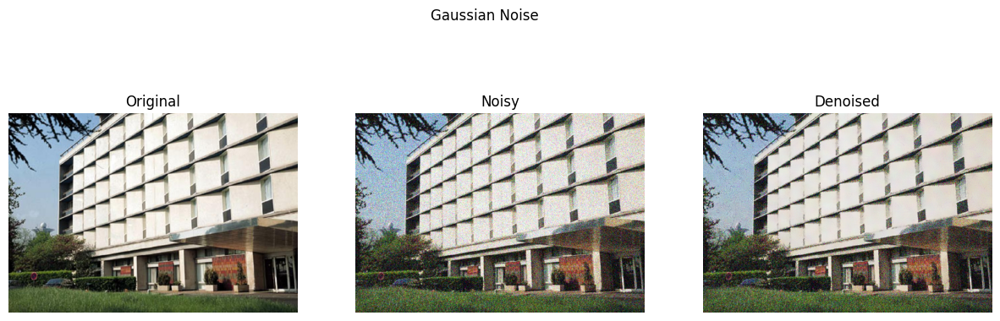

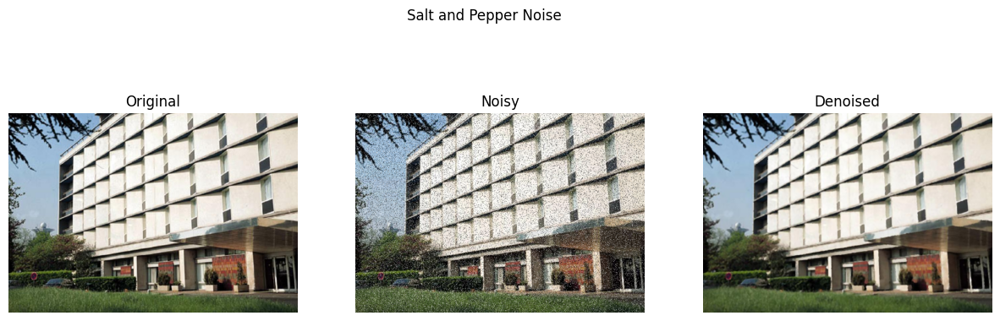

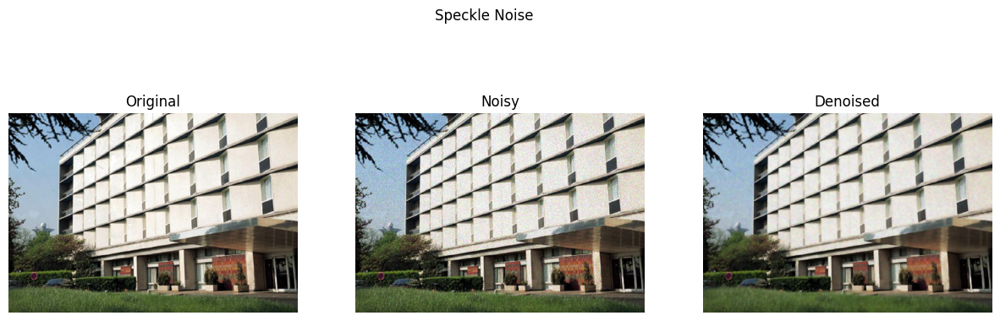

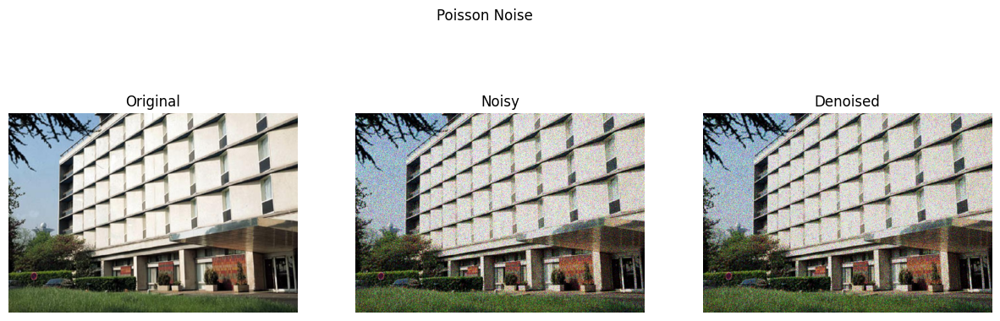

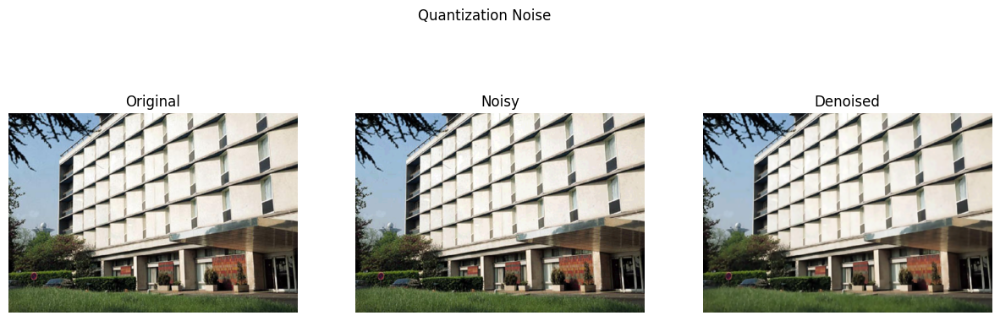

...

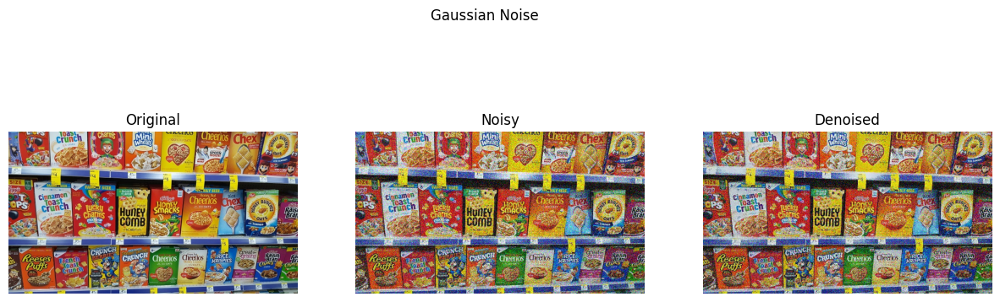

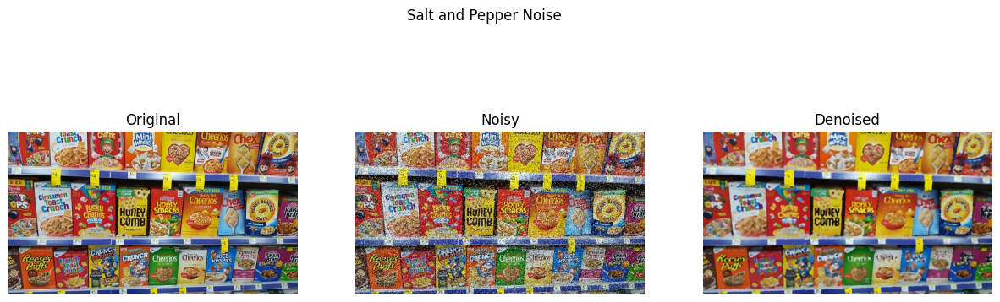

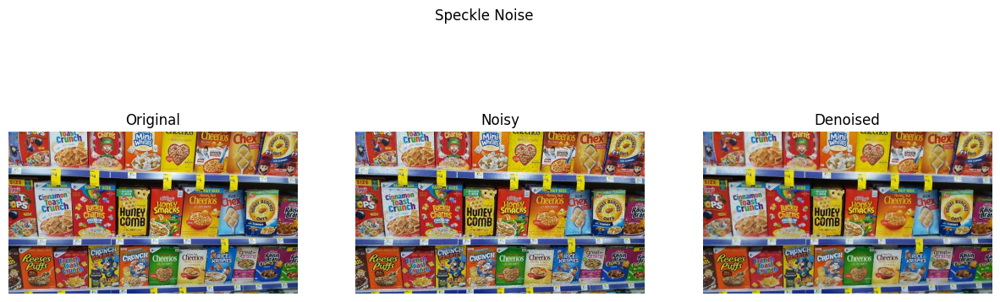

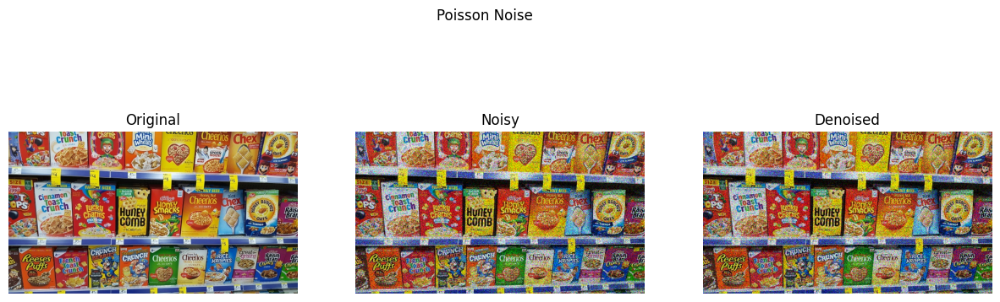

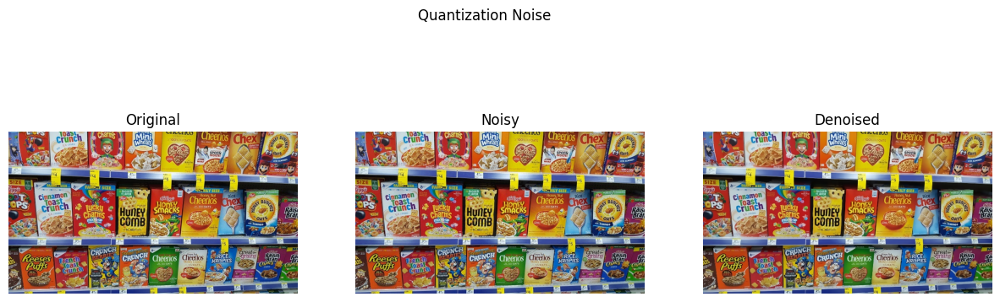

In [27]:
img_paths = ['building.jpg', 'giraffes.jpg', 'many_cereals.jpg']
for img_path in img_paths:
  img = load_image(img_path)
  noisy = add_gaussian_noise(img, sigma=50)
  clean = denoise_gaussian(noisy)
  plot_image(img, noisy, clean, noise_title = "Gaussian Noise")
  noisy = add_salt_pepper_noise(img, amount=0.15)
  clean = denoise_salt_pepper(noisy)
  plot_image(img, noisy, clean, noise_title = "Salt and Pepper Noise")
  noisy = add_speckle_noise(img, variance=0.15)
  clean = denoise_speckle(noisy)
  plot_image(img, noisy, clean, noise_title = "Speckle Noise")
  noisy = add_poisson_noise(img, peak=10)
  clean = denoise_poisson(noisy)
  plot_image(img, noisy, clean, noise_title = "Poisson Noise")
  noisy = add_quantization_noise(img, levels=32)
  clean = denoise_quantization(noisy)
  plot_image(img, noisy, clean, noise_title = "Quantization Noise")